# SUPERSTORE DATASET ANALYSIS

## Data import and preparation

In [1]:
import kagglehub

path = kagglehub.dataset_download(
    "vivek468/superstore-dataset-final"
)

print("Dataset location:", path)

Dataset location: C:\Users\nkras\.cache\kagglehub\datasets\vivek468\superstore-dataset-final\versions\1


In [2]:
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

csv_files = list(Path(path).rglob("*.csv"))

print(csv_files)

[WindowsPath('C:/Users/nkras/.cache/kagglehub/datasets/vivek468/superstore-dataset-final/versions/1/Sample - Superstore.csv')]


In [3]:
df = pd.read_csv(csv_files[0], encoding='latin1')

df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


In [4]:
display(df.shape)
df.describe().T

(9994, 21)

,count,mean,std,min,25%,50%,75%,max
Row ID,9994.0,4997.500000,2885.163629,1.000,2499.25000,4997.5000,7495.750,9994.000
Postal Code,9994.0,55190.379428,32063.693350,1040.000,23223.00000,56430.5000,90008.000,99301.000
Sales,9994.0,229.858001,623.245101,0.444,17.28000,54.4900,209.940,22638.480
Quantity,9994.0,3.789574,2.225110,1.000,2.00000,3.0000,5.000,14.000
Discount,9994.0,0.156203,0.206452,0.000,0.00000,0.2000,0.200,0.800
Profit,9994.0,28.656896,234.260108,-6599.978,1.72875,8.6665,29.364,8399.976


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   object 
 2   Order Date     9994 non-null   object 
 3   Ship Date      9994 non-null   object 
 4   Ship Mode      9994 non-null   object 
 5   Customer ID    9994 non-null   object 
 6   Customer Name  9994 non-null   object 
 7   Segment        9994 non-null   object 
 8   Country        9994 non-null   object 
 9   City           9994 non-null   object 
 10  State          9994 non-null   object 
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   object 
 13  Product ID     9994 non-null   object 
 14  Category       9994 non-null   object 
 15  Sub-Category   9994 non-null   object 
 16  Product Name   9994 non-null   object 
 17  Sales          9994 non-null   float64
 18  Quantity

In [6]:
# Checking for missing, NA, and duplicated values
missing_values = pd.DataFrame({
    'Missing Count': df.isna().sum(),
    'Missing %': df.isna().mean() * 100,
    'Duplicates': df.duplicated().sum()
})

display(missing_values)

,Missing Count,Missing %,Duplicates
Row ID,0,0.0,0
Order ID,0,0.0,0
Order Date,0,0.0,0
Ship Date,0,0.0,0
Ship Mode,0,0.0,0
Customer ID,0,0.0,0
Customer Name,0,0.0,0
Segment,0,0.0,0
Country,0,0.0,0
City,0,0.0,0


In [7]:
# Converting date columns into the date format and creating new columns for year, month and day
date_columns = ['Order Date', 'Ship Date']

for col in date_columns:
    df[col] = pd.to_datetime(df[col], dayfirst=False)

df['Order_Year'] = df['Order Date'].dt.year
df['Order_Month'] = df['Order Date'].dt.month
df['Order_Day'] = df['Order Date'].dt.day
df['Order_Weekday'] = df['Order Date'].dt.day_name()

In [8]:
# Calculating delivery time
df['Shipping_Days'] = (df['Ship Date'] - df['Order Date']).dt.days

df['Shipping_Days'].describe()

count    9994.000000
mean        3.958175
std         1.747567
min         0.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         7.000000
Name: Shipping_Days, dtype: float64

## Commercial performance overview

In [9]:
# Calculating KPIs
total_revenue = df['Sales'].sum()
total_profit = df['Profit'].sum()

profit_margin = (total_profit / total_revenue) * 100

unique_orders = df['Order ID'].nunique()

unique_customers = df['Customer ID'].nunique()

avg_order_value = total_revenue / unique_orders

avg_profit = df['Profit'].mean()

print(f"Total revenue: ${total_revenue:,.2f}")
print(f"Total profit: ${total_profit:,.2f}")
print(f"Overall profit margin: {profit_margin:.2f}%")
print(f"Average order value: ${avg_order_value:,.2f}")
print(f"Average profit: ${avg_profit:,.2f}")
print(f"Number of unique orders: {unique_orders:,}")
print(f"Number of unique customers: {unique_customers:,}")

Total revenue: $2,297,200.86
Total profit: $286,397.02
Overall profit margin: 12.47%
Average order value: $458.61
Average profit: $28.66
Number of unique orders: 5,009
Number of unique customers: 793


In [10]:
# Calculating total revenue and profit by month
monthly_data = (
    df.groupby(df['Order Date'].dt.to_period('M'))
    .agg(Revenue=('Sales', 'sum'),
        Profit=('Profit', 'sum'),)
)

# Converting the monthly index to timestamps for plotting
monthly_data.index = monthly_data.index.to_timestamp()

display(monthly_data.head())

,Revenue,Profit
Order Date,,
2014-01-01,14236.895,2450.1907
2014-02-01,4519.892,862.3084
2014-03-01,55691.009,498.7299
2014-04-01,28295.345,3488.8352
2014-05-01,23648.287,2738.7096


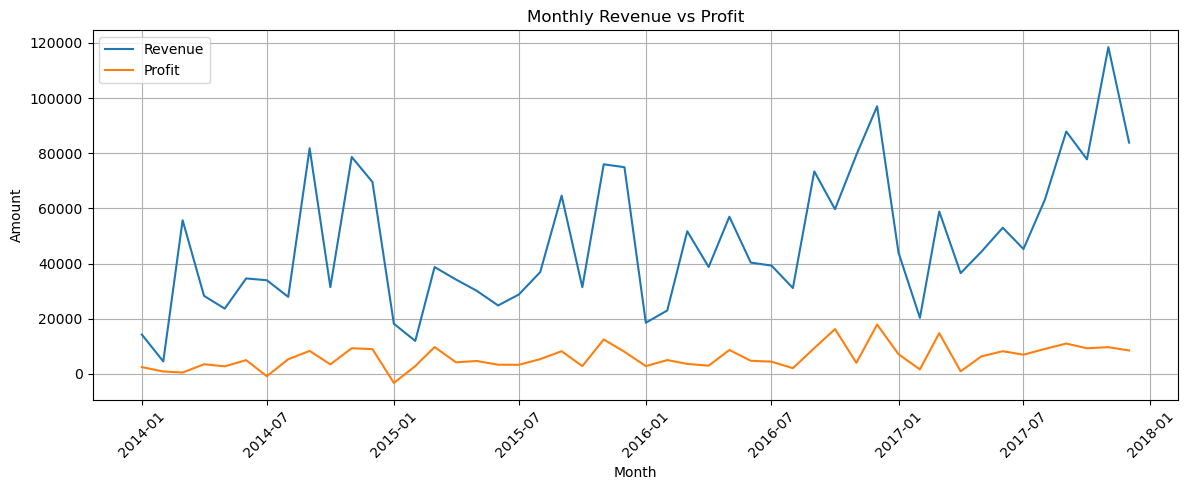

In [11]:
# Plotting monthly revenue vs profit
plt.figure(figsize=(12, 5))

plt.plot(monthly_data.index, monthly_data['Revenue'], label='Revenue')

plt.plot(monthly_data.index, monthly_data['Profit'], label='Profit')

plt.title('Monthly Revenue vs Profit')
plt.xlabel('Month')
plt.ylabel('Amount')
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

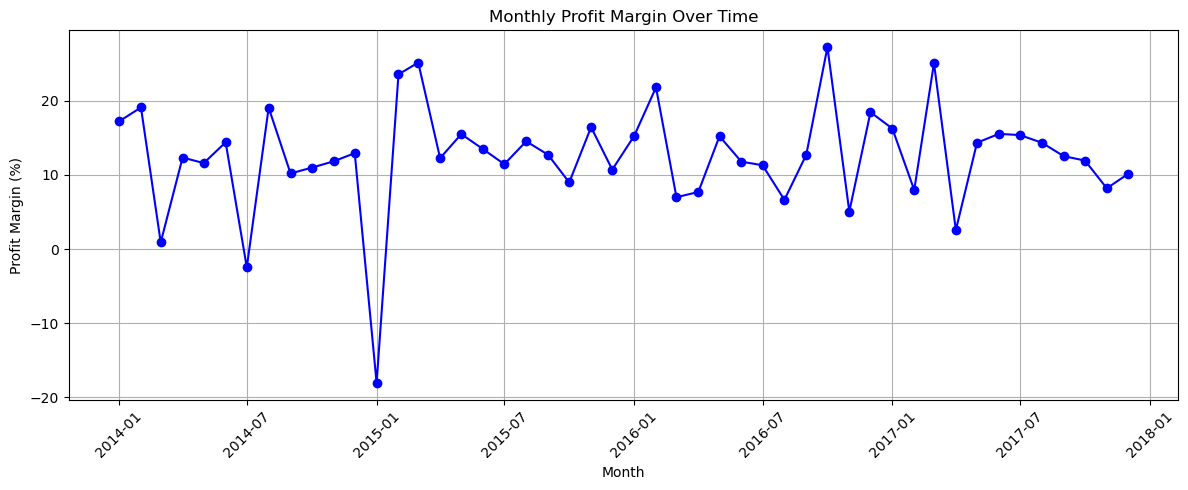

In [12]:
# Plotting monthly profit margin

monthly_data['Profit margin'] = (monthly_data['Profit'] / monthly_data['Revenue']) * 100

plt.figure(figsize=(12, 5))

plt.plot(monthly_data.index, monthly_data['Profit margin'], color='blue', marker='o')

plt.title('Monthly Profit Margin Over Time')
plt.ylabel('Profit Margin (%)')
plt.xlabel('Month')
plt.grid(True)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Product & category profitability

In [13]:
# Finding which product categories generate the most revenue and profit
category_stats = (
    df.groupby(['Category', 'Sub-Category'])
    .agg(
        Revenue=('Sales', 'sum'),
        Profit=('Profit', 'sum')
    )
)

category_stats['Profit_Margin'] = (category_stats['Profit'] / category_stats['Revenue']) * 100

category_stats.sort_values('Profit', ascending=False)

Revenue      Profit  Profit_Margin
Category        Sub-Category                                        
Technology      Copiers       149528.0300  55617.8249      37.195585
                Phones        330007.0540  44515.7306      13.489327
                Accessories   167380.3180  41936.6357      25.054700
Office Supplies Paper          78479.2060  34053.5693      43.391837
                Binders       203412.7330  30221.7633      14.857361
Furniture       Chairs        328449.1030  26590.1663       8.095673
Office Supplies Storage       223843.6080  21278.8264       9.506113
                Appliances    107532.1610  18138.0054      16.867517
Furniture       Furnishings    91705.1640  13059.1436      14.240358
Office Supplies Envelopes      16476.4020   6964.1767      42.267582
                Art            27118.7920   6527.7870      24.071083
                Labels         12486.3120   5546.2540      44.418672
Technology      Machines      189238.6310   3384.7569       1.788618
Office Supplies Fasteners       3024.2800    949.5182      31.396504
                Supplies       46673.5380  -1189.0995      -2.547695
Furniture       Bookcases     114879.9963  -3472.5560      -3.022768
                Tables        206965.5320 -17725.4811      -8.564460

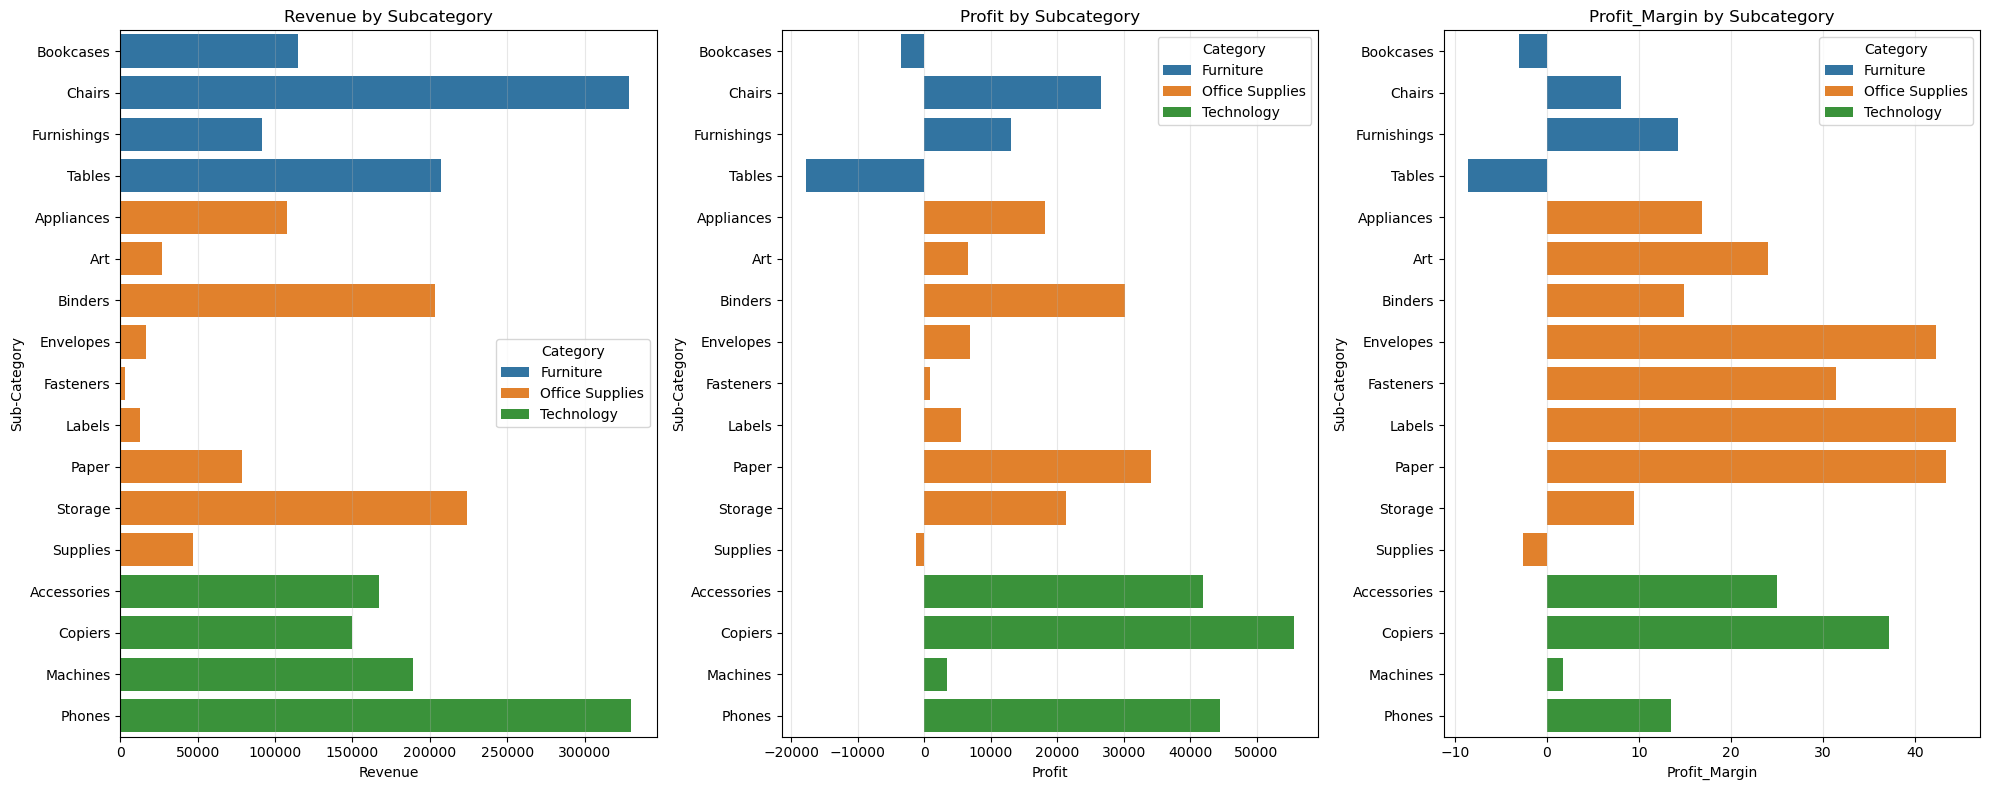

In [14]:
# Visualising category performance
metrics = ['Revenue', 'Profit', 'Profit_Margin']

fig, axes = plt.subplots(1, 3, figsize=(20, 8))

for ax, metric in zip(axes, metrics):

    sns.barplot(
        data=category_stats,
        x=metric,
        y='Sub-Category',
        hue='Category',
        ax=ax
    )

    ax.set_title(f'{metric} by Subcategory')
    ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

In [15]:
# Checking if high-revenue products necessarily generate high profits
product_stats = (
    df.groupby(['Product ID', 'Product Name']).agg(
    Revenue=('Sales', 'sum'),
     Profit=('Profit', 'sum'),
     Quantity=('Quantity', 'sum')
    ).reset_index()
)

product_stats['Profit_Margin'] = (product_stats['Profit'] / product_stats['Revenue']) * 100

display(product_stats)

,Product ID,Product Name,Revenue,Profit,Quantity,Profit_Margin
0,FUR-BO-10000112,"Bush Birmingham Collection Bookcase, Dark Cherry",825.174,-117.8820,9,-14.285714
1,FUR-BO-10000330,"Sauder Camden County Barrister Bookcase, Plank...",1064.624,24.1960,10,2.272727
2,FUR-BO-10000362,Sauder Inglewood Library Bookcases,2154.348,311.1836,14,14.444444
3,FUR-BO-10000468,O'Sullivan 2-Shelf Heavy-Duty Bookcases,723.842,-133.1092,21,-18.389262
4,FUR-BO-10000711,"Hon Metal Bookcases, Gray",851.760,229.9752,12,27.000000
...,...,...,...,...,...,...
1889,TEC-PH-10004912,Cisco SPA112 2 Port Phone Adapter,516.530,87.3705,11,16.914894
1890,TEC-PH-10004922,RCA Visys Integrated PBX 8-Line Router,1085.238,130.6305,19,12.037037
1891,TEC-PH-10004924,"SKILCRAFT Telephone Shoulder Rest, 2"" x 6.5"" x...",56.164,13.0064,8,23.157895
1892,TEC-PH-10004959,Classic Ivory Antique Telephone ZL1810,341.666,40.1960,4,11.764706


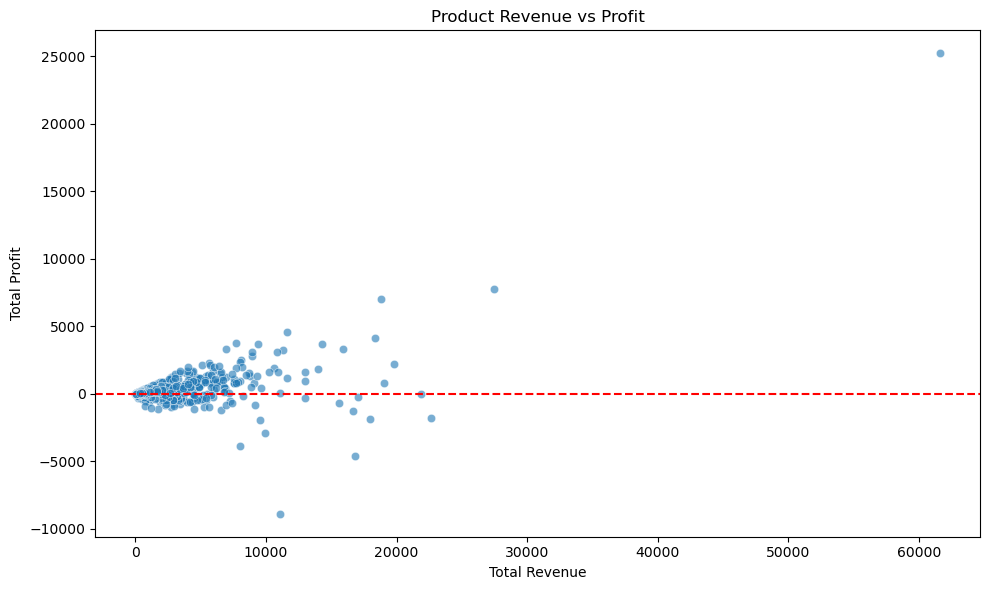

In [16]:
# Creating a revenue vs profit scatterplot
fig, ax = plt.subplots(figsize=(10, 6))

sns.scatterplot(data=product_stats, x='Revenue', y='Profit', alpha=0.6, ax=ax)

ax.axhline(0, color='red', linestyle='--')

ax.set_title('Product Revenue vs Profit')
ax.set_xlabel('Total Revenue')
ax.set_ylabel('Total Profit')

plt.tight_layout()
plt.show()

In [17]:
# Calculating correlation
correlation = product_stats['Revenue'].corr(product_stats['Profit'], method='pearson')

print(f"Correlation between revenue and profit is {correlation:.2f}")

Correlation between revenue and profit is 0.59


In [18]:
# Finding high-revenue but low-profit products
revenue_threshold = product_stats['Revenue'].quantile(0.75)

high_revenue = product_stats[product_stats['Revenue'] >= revenue_threshold]

high_revenue_losses = high_revenue[high_revenue['Profit'] < 0]

display(high_revenue_losses.sort_values('Profit'))

,Product ID,Product Name,Revenue,Profit,Quantity,Profit_Margin
1645,TEC-MA-10000418,Cubify CubeX 3D Printer Double Head Print,11099.963,-8.879970e+03,9,-8.000000e+01
1650,TEC-MA-10000822,Lexmark MX611dhe Monochrome Laser Printer,16829.901,-4.589973e+03,18,-2.727273e+01
1696,TEC-MA-10004125,Cubify CubeX 3D Printer Triple Head Print,7999.980,-3.839990e+03,4,-4.800000e+01
326,FUR-TA-10000198,Chromcraft Bull-Nose Wood Oval Conference Tabl...,9917.640,-2.876116e+03,27,-2.900000e+01
344,FUR-TA-10001889,Bush Advantage Collection Racetrack Conference...,9544.725,-1.934398e+03,33,-2.026667e+01
...,...,...,...,...,...,...
39,FUR-BO-10003966,"Sauder Facets Collection Library, Sky Alder Fi...",1427.683,-8.549000e+00,10,-5.988024e-01
1379,OFF-ST-10001963,Tennsco Regal Shelving Units,1764.534,-6.084600e+00,18,-3.448276e-01
1336,OFF-ST-10000736,Carina Double Wide Media Storage Towers in Nat...,3028.652,-3.239200e+00,39,-1.069519e-01
1467,OFF-SU-10003505,Premier Electric Letter Opener,2641.608,-7.105427e-15,24,-2.689811e-16


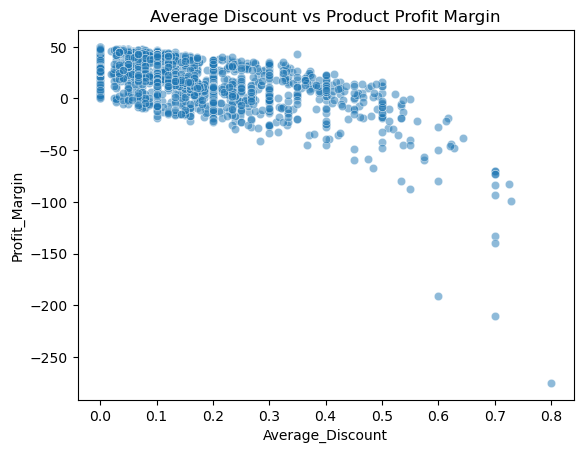

In [19]:
# Investigating the impact of discounts on profit
discount_analysis = (
    df.groupby(['Product ID', 'Product Name']).agg(
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Average_Discount=('Discount', 'mean')
    ).reset_index()
)

discount_analysis['Profit_Margin'] = (discount_analysis['Profit'] / discount_analysis['Revenue']) * 100

sns.scatterplot(data=discount_analysis, x='Average_Discount', y='Profit_Margin', alpha=0.5)

plt.title('Average Discount vs Product Profit Margin')
plt.show()

## Customer segment analysis

In [20]:
segment_analysis = (
    df.groupby(['Segment']).agg(
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Unique_Orders=('Order ID', 'nunique')
    ).reset_index()
)

segment_analysis['Profit_Margin'] = (segment_analysis['Profit'] / segment_analysis['Revenue']) * 100
segment_analysis['Average_order_value'] = (segment_analysis['Revenue'] / segment_analysis['Unique_Orders'])

segment_analysis.sort_values('Profit_Margin', ascending=False)

,Segment,Revenue,Profit,Unique_Orders,Profit_Margin,Average_order_value
2,Home Office,4.296531e+05,60298.6785,909,14.034269,472.665730
1,Corporate,7.061464e+05,91979.1340,1514,13.025506,466.411075
0,Consumer,1.161401e+06,134119.2092,2586,11.548050,449.111116


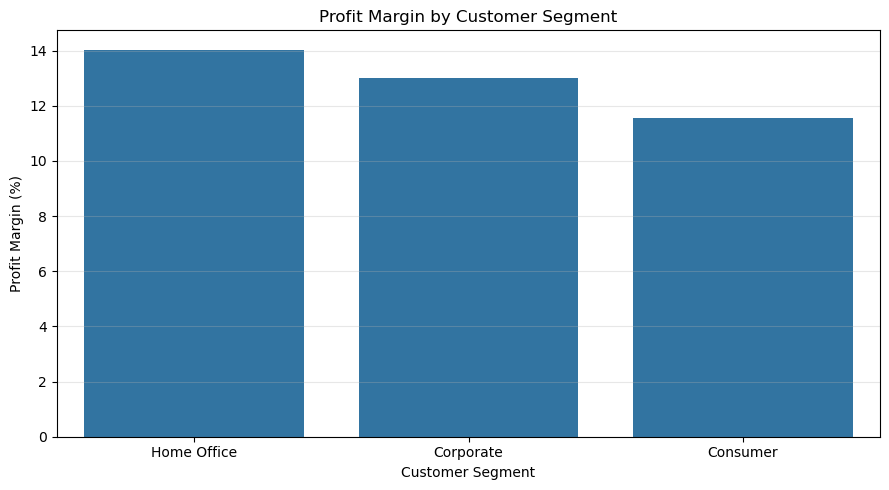

In [21]:
# Visualising profit margins
fig, ax = plt.subplots(figsize=(9, 5))

sns.barplot(data=segment_analysis.sort_values('Profit_Margin', ascending=False), x='Segment', y='Profit_Margin', ax=ax)

ax.set_title('Profit Margin by Customer Segment')
ax.set_xlabel('Customer Segment')
ax.set_ylabel('Profit Margin (%)')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

In [22]:
# Investigating customer purchasing behaviour
customer_stats = (
    df.groupby(['Customer ID', 'Segment']).agg(
    Revenue=('Sales', 'sum'),
    Profit=('Profit', 'sum'),
    Orders=('Order ID', 'nunique'),
    Quantity=('Quantity', 'sum')
    ).reset_index()
)

customer_stats['Average_Order_Value'] = (customer_stats['Revenue'] / customer_stats['Orders'])

customer_stats.head()

,Customer ID,Segment,Revenue,Profit,Orders,Quantity,Average_Order_Value
0,AA-10315,Consumer,5563.560,-362.8825,5,30,1112.712000
1,AA-10375,Consumer,1056.390,277.3824,9,41,117.376667
2,AA-10480,Consumer,1790.512,435.8274,4,36,447.628000
3,AA-10645,Consumer,5086.935,857.8033,6,64,847.822500
4,AB-10015,Consumer,886.156,129.3465,3,13,295.385333


In [23]:
# Comparing behaviour between segments
segment_behaviour = (
    customer_stats.groupby('Segment').agg(
        Avg_Revenue_Per_Customer=('Revenue', 'mean'),
        Avg_Orders_Per_Customer=('Orders', 'mean'),
        Avg_Order_Value=('Average_Order_Value', 'mean'),
        Avg_Quantity=('Quantity', 'mean'),
        Customer_Count=('Customer ID', 'nunique')).reset_index())

display(segment_behaviour.round(2))

,Segment,Avg_Revenue_Per_Customer,Avg_Orders_Per_Customer,Avg_Order_Value,Avg_Quantity,Customer_Count
0,Consumer,2839.61,6.32,446.50,47.73,409
1,Corporate,2992.15,6.42,476.54,49.19,236
2,Home Office,2903.06,6.14,471.71,45.57,148


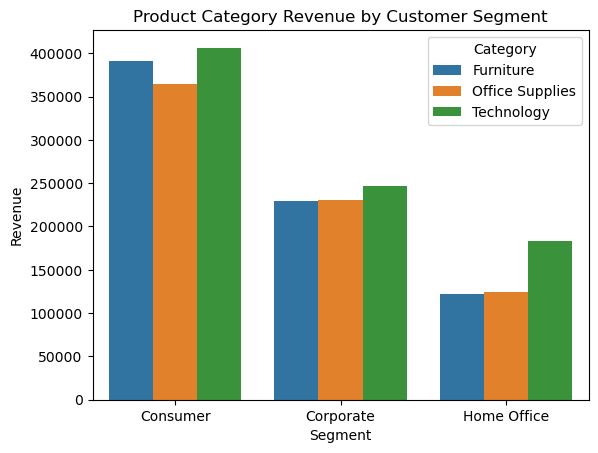

In [24]:
# Investigating purchasing preferences
segment_categories = (df.groupby(['Segment', 'Category']).agg(Revenue=('Sales', 'sum')).reset_index())

sns.barplot(data=segment_categories,x='Segment',y='Revenue',hue='Category')

plt.title('Product Category Revenue by Customer Segment')
plt.ylabel('Revenue')
plt.show()

In [25]:
# Customer revenue contribution
customer_ranked = customer_stats.sort_values('Revenue',ascending=False).copy()

customer_ranked['Cumulative_Revenue'] = (customer_ranked['Revenue'].cumsum())

customer_ranked['Cumulative_Revenue_Pct'] = (customer_ranked['Cumulative_Revenue'] /customer_ranked['Revenue'].sum()) * 100

customer_ranked['Cumulative_Customer_Pct'] = (range(1, len(customer_ranked) + 1))

customer_ranked['Cumulative_Customer_Pct'] = (customer_ranked['Cumulative_Customer_Pct'] /len(customer_ranked)) * 100

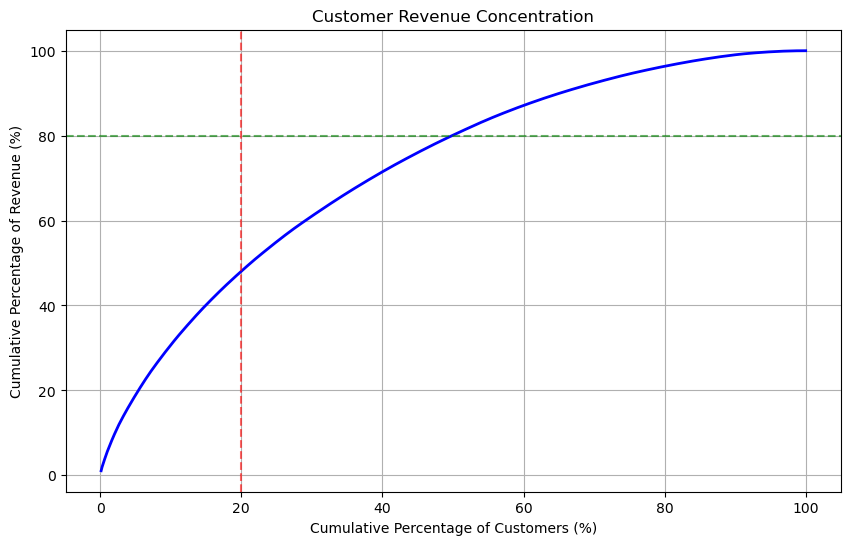

In [26]:
# Visualising customer revenue concentration
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(customer_ranked['Cumulative_Customer_Pct'], customer_ranked['Cumulative_Revenue_Pct'], color='blue', linewidth=2)

ax.axvline(20, color='red', linestyle='--', alpha=0.6)
ax.axhline(80, color='green', linestyle='--', alpha=0.6)

ax.set_title('Customer Revenue Concentration')
ax.set_xlabel('Cumulative Percentage of Customers (%)')
ax.set_ylabel('Cumulative Percentage of Revenue (%)')

ax.grid()

plt.show()

In [27]:
top_20_count = int(np.ceil(len(customer_ranked) * 0.20))

top_20_revenue = (customer_ranked.head(top_20_count)['Revenue'].sum())

revenue_share = (top_20_revenue / customer_ranked['Revenue'].sum()) * 100

print(f"Top 20% of customers generate " f"{revenue_share:.2f}% of total revenue.")

Top 20% of customers generate 48.15% of total revenue.


## Regional performance

In [28]:
# Determining regions generating the most revenue and profit
regional_analysis = (
    df.groupby('Region')
    .agg(
        Revenue=('Sales', 'sum'),
        Profit=('Profit', 'sum'),
        Avg_Discount=('Discount', 'mean'),
        Orders=('Order ID', 'nunique')
    ).reset_index()
)

regional_analysis['Profit_Margin'] = (regional_analysis['Profit'] / regional_analysis['Revenue']) * 100
regional_analysis['Revenue_Share'] = (regional_analysis['Revenue'] / regional_analysis['Revenue'].sum()) * 100

regional_analysis.sort_values('Revenue', ascending=False)

,Region,Revenue,Profit,Avg_Discount,Orders,Profit_Margin,Revenue_Share
3,West,725457.8245,108418.4489,0.109335,1611,14.944831,31.580078
1,East,678781.2400,91522.7800,0.145365,1401,13.483399,29.548188
0,Central,501239.8908,39706.3625,0.240353,1175,7.921629,21.819594
2,South,391721.9050,46749.4303,0.147253,822,11.934342,17.052140


In [29]:
# Analysing city performance
city_analysis = (df.groupby(['Region', 'State', 'City'])
    .agg(
        Revenue=('Sales', 'sum'),
        Profit=('Profit', 'sum'),
        Avg_Discount=('Discount', 'mean'),
        Orders=('Order ID', 'nunique')
    ).reset_index()
)

city_analysis['Profit_Margin'] = (city_analysis['Profit'] / city_analysis['Revenue']) * 100

loss_making_cities = city_analysis[city_analysis['Profit'] < 0]

display(loss_making_cities.sort_values('Profit'))

,Region,State,City,Revenue,Profit,Avg_Discount,Orders,Profit_Margin
291,East,Pennsylvania,Philadelphia,109077.0130,-13837.7674,0.326816,265,-12.686236
146,Central,Texas,Houston,64504.7604,-10153.5485,0.379682,188,-15.740774
167,Central,Texas,San Antonio,21843.5280,-7299.0502,0.383051,27,-33.415162
275,East,Ohio,Lancaster,8202.6250,-7149.6180,0.312903,15,-87.162561
7,Central,Illinois,Chicago,48539.5410,-6654.5688,0.383758,171,-13.709583
...,...,...,...,...,...,...,...,...
339,South,Florida,Ormond Beach,2.8080,-1.9656,0.700000,1,-70.000000
342,South,Florida,Pensacola,2.2140,-1.4760,0.700000,1,-66.666667
269,East,Ohio,Elyria,1.8240,-1.3984,0.700000,1,-76.666667
287,East,Pennsylvania,Altoona,20.4510,-1.1835,0.450000,1,-5.787003


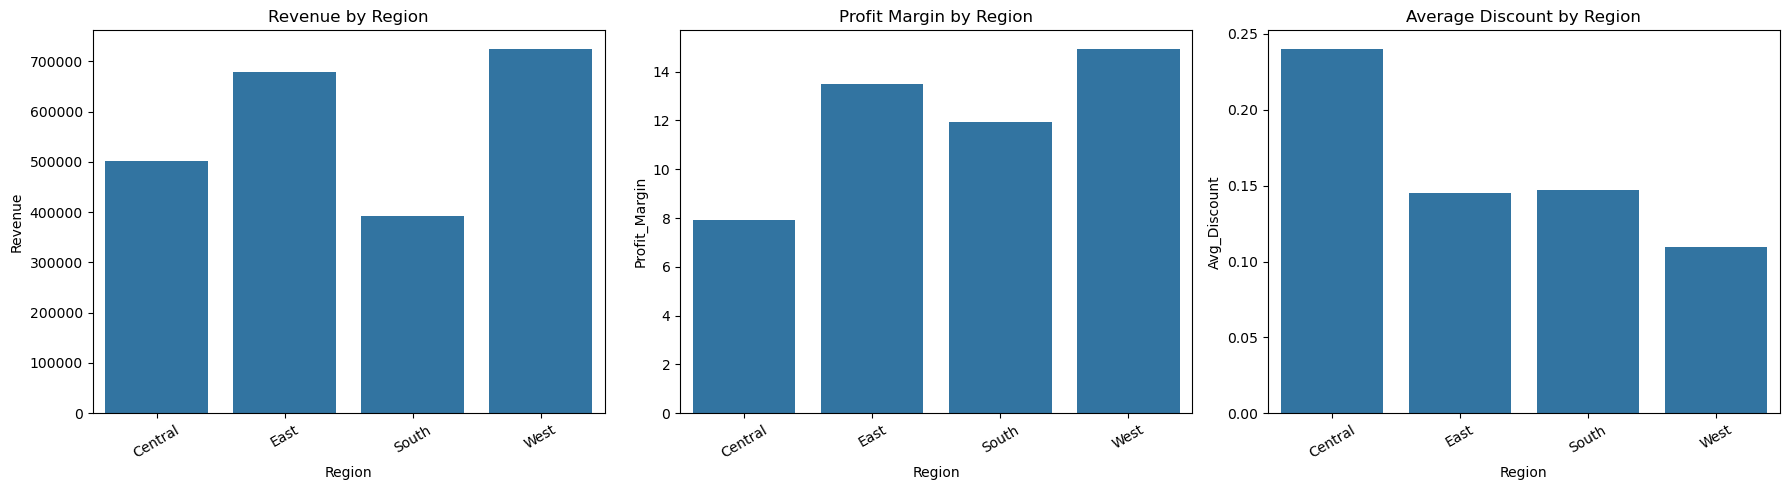

In [30]:
metrics = ['Revenue', 'Profit_Margin', 'Avg_Discount']

titles = ['Revenue by Region', 'Profit Margin by Region', 'Average Discount by Region']

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric, title in zip(axes, metrics, titles):
    sns.barplot(data=regional_analysis, x='Region', y=metric, ax=ax)
    ax.set_title(title)
    ax.tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

## Financial performance and risk

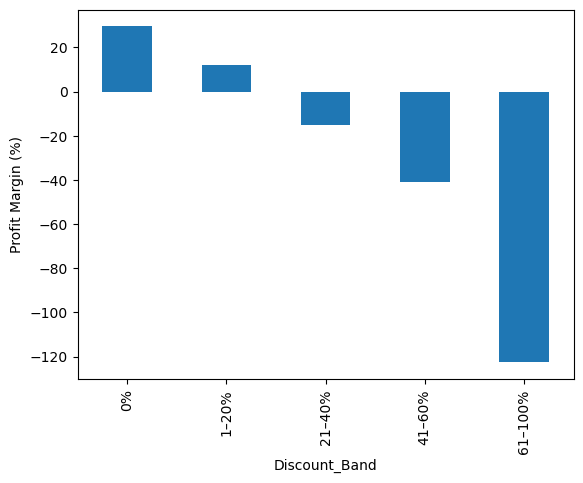

In [31]:
df['Discount_Band'] = pd.cut(
    df['Discount'],
    bins=[-0.01, 0, 0.2, 0.4, 0.6, 1],
    labels=['0%', '1–20%', '21–40%', '41–60%', '61–100%']
)

discount_analysis = df.groupby('Discount_Band', observed=True)[['Sales', 'Profit']].sum()

discount_analysis['Profit_Margin'] = (discount_analysis['Profit'] / discount_analysis['Sales']) * 100

discount_analysis['Profit_Margin'].plot(kind='bar')
plt.ylabel('Profit Margin (%)')
plt.show()

In [32]:
# Concentration of profit among customers
customer_profit = df.groupby('Customer ID')['Profit'].sum()
customer_profit = customer_profit.sort_values(ascending=False)

top_20 = int((len(customer_profit) * 0.20))

profit_share = (customer_profit.head(top_20).sum() / customer_profit.sum()) * 100

print(f"Top 20% of customers contribute {profit_share:.2f}% of net profit")

Top 20% of customers contribute 81.43% of net profit


In [33]:
loss_sales = df.loc[df['Profit'] < 0, 'Sales'].sum()

loss_sales_pct = (loss_sales / df['Sales'].sum()) * 100

print(f"{loss_sales_pct:.2f}% of sales comes from loss-making transactions")

20.40% of sales comes from loss-making transactions


In [34]:
risk_analysis = regional_analysis[
    ['Region', 'Revenue', 'Profit',
     'Profit_Margin', 'Avg_Discount']
].sort_values('Profit_Margin')

display(risk_analysis)

,Region,Revenue,Profit,Profit_Margin,Avg_Discount
0,Central,501239.8908,39706.3625,7.921629,0.240353
2,South,391721.9050,46749.4303,11.934342,0.147253
1,East,678781.2400,91522.7800,13.483399,0.145365
3,West,725457.8245,108418.4489,14.944831,0.109335
